<a href="https://colab.research.google.com/github/nidhi2407032-dotcom/CPOT_TENS-Project/blob/main/GSR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import zipfile
import glob

def explore_and_extract(folder_path):
    print(f"\n{'='*60}\nExploring: {folder_path}\n{'='*60}")

    zip_files = glob.glob(os.path.join(folder_path, "**/*.zip"), recursive=True)
    for z in zip_files:
        print(f"Extracting: {z}")
        with zipfile.ZipFile(z, 'r') as zf:
            zf.extractall(folder_path)

    all_files = glob.glob(os.path.join(folder_path, "**/*"), recursive=True)
    all_files = [f for f in all_files if os.path.isfile(f)]

    print(f"\nTotal files found: {len(all_files)}")
    extensions = {}
    for f in all_files:
        ext = os.path.splitext(f)[1].lower()
        extensions[ext] = extensions.get(ext, 0) + 1
    print("File types found:", extensions)

    print("\nFirst 10 file paths:")
    for f in all_files[:10]:
        print(" ", f)

    return all_files

gsr_files = explore_and_extract("/content/gsr")


Exploring: /content/gsr

Total files found: 0
File types found: {}

First 10 file paths:


Extracting: /content/gsr_data1.zip to /content/gsr_extracted_data
Found CSV files: ['/content/gsr_extracted_data/Low_MWL/Low_MWL/p8l.csv', '/content/gsr_extracted_data/Low_MWL/Low_MWL/p14l.csv', '/content/gsr_extracted_data/Low_MWL/Low_MWL/p23l.csv', '/content/gsr_extracted_data/Low_MWL/Low_MWL/p18l.csv', '/content/gsr_extracted_data/Low_MWL/Low_MWL/p21l.csv', '/content/gsr_extracted_data/Low_MWL/Low_MWL/p6l.csv', '/content/gsr_extracted_data/Low_MWL/Low_MWL/p10l.csv', '/content/gsr_extracted_data/Low_MWL/Low_MWL/p12l.csv', '/content/gsr_extracted_data/Low_MWL/Low_MWL/p15l.csv', '/content/gsr_extracted_data/Low_MWL/Low_MWL/p5l.csv', '/content/gsr_extracted_data/Low_MWL/Low_MWL/p24l.csv', '/content/gsr_extracted_data/Low_MWL/Low_MWL/p2l.csv', '/content/gsr_extracted_data/Low_MWL/Low_MWL/p17l.csv', '/content/gsr_extracted_data/Low_MWL/Low_MWL/p22l.csv', '/content/gsr_extracted_data/Low_MWL/Low_MWL/p25l.csv', '/content/gsr_extracted_data/Low_MWL/Low_MWL/p11l.csv', '/content/gsr_extracted_

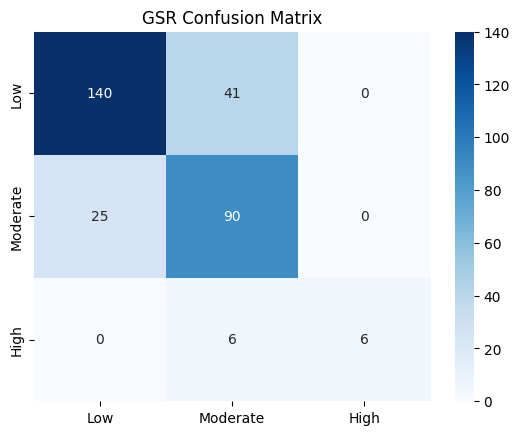


=== Feature Importance ===
gsr_slope    0.511869
gsr_range    0.320653
gsr_std      0.116881
gsr_mean     0.031525
gsr_max      0.019072
dtype: float64


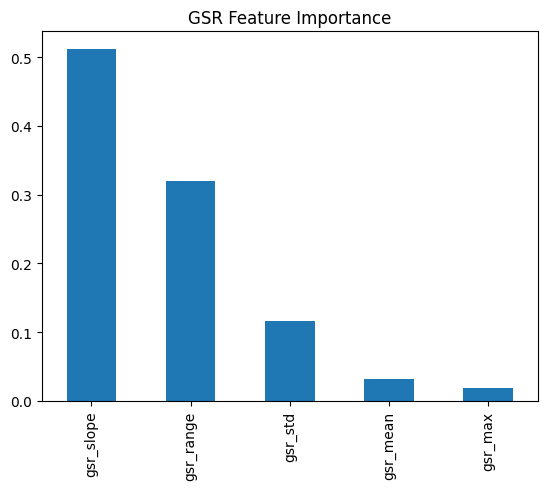


=== Value Ranges by CPOT Class ===
           gsr_mean              gsr_std               gsr_slope         \
                min    max  mean     min    max   mean       min    max   
cpot_class                                                                
Low           0.087  0.133  0.11   0.000  0.001  0.001    -0.003  0.001   
Moderate      0.087  0.133  0.11   0.000  0.001  0.001    -0.004  0.002   
High          0.092  0.132  0.11   0.001  0.001  0.001    -0.001  0.003   

                  gsr_max               gsr_range                
             mean     min    max   mean       min    max   mean  
cpot_class                                                       
Low        -0.000   0.088  0.134  0.111     0.001  0.003  0.002  
Moderate    0.000   0.089  0.134  0.111     0.001  0.004  0.002  
High        0.002   0.093  0.133  0.111     0.002  0.004  0.003  

Saved: gsr_model.pkl


In [ ]:

import os, glob, zipfile
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

ZIP_FILE_PATH = "/content/gsr_data1.zip"
EXTRACT_DIR = "/content/gsr_extracted_data"


os.makedirs(EXTRACT_DIR, exist_ok=True)


if os.path.exists(ZIP_FILE_PATH) and zipfile.is_zipfile(ZIP_FILE_PATH):
    print(f"Extracting: {ZIP_FILE_PATH} to {EXTRACT_DIR}")
    with zipfile.ZipFile(ZIP_FILE_PATH, 'r') as zf:
        zf.extractall(EXTRACT_DIR)
else:
    print(f"Error: {ZIP_FILE_PATH} not found or is not a valid zip file.")

csv_files = glob.glob(f"{EXTRACT_DIR}/**/*.csv", recursive=True)
print("Found CSV files:", csv_files)
assert len(csv_files) > 0, "No CSV found after extraction — please check the zip file content."

df = pd.read_csv(csv_files[0])
print(df.shape)
print("Columns:", list(df.columns))

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Numeric columns available:", numeric_cols)

SIGNAL_COL = numeric_cols[0]
print("Using signal column:", SIGNAL_COL)

signal = df[SIGNAL_COL].dropna().values.astype(np.float32)

WINDOW = 50
n_windows = len(signal) // WINDOW
signal = signal[: n_windows * WINDOW].reshape(n_windows, WINDOW)

features = pd.DataFrame({
    "gsr_mean": np.mean(signal, axis=1),
    "gsr_std": np.std(signal, axis=1),
    "gsr_slope": signal[:, -1] - signal[:, 0],
    "gsr_max": np.max(signal, axis=1),
    "gsr_range": np.ptp(signal, axis=1),
})

raw_score = (0.4*features["gsr_std"] + 0.35*features["gsr_slope"].clip(lower=0) + 0.25*features["gsr_range"])
raw_score = (raw_score - raw_score.min()) / (raw_score.max() - raw_score.min() + 1e-8)

np.random.seed(42)
noise = np.random.normal(0, 0.12, size=len(raw_score))
noisy_score = np.clip(raw_score + noise, 0, 1)
cpot_score = noisy_score * 8
cpot_class = pd.cut(cpot_score, bins=[-1, 2.67, 5.34, 9], labels=["Low", "Moderate", "High"])

X = features
y = cpot_class

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=100, max_depth=4, min_samples_leaf=5, random_state=42)
model.fit(X_train, y_train)
preds = model.predict(X_test)

acc = accuracy_score(y_test, preds)
print(f"\n=== GSR Model Accuracy: {acc:.4f} ===")
print(classification_report(y_test, preds))

cm = confusion_matrix(y_test, preds, labels=["Low", "Moderate", "High"])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Low","Moderate","High"], yticklabels=["Low","Moderate","High"])
plt.title("GSR Confusion Matrix"); plt.show()

print("\n=== Feature Importance ===")
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance)
importance.plot(kind='bar', title="GSR Feature Importance"); plt.show()

print("\n=== Value Ranges by CPOT Class ===")
features_labeled = features.copy()
features_labeled["cpot_class"] = cpot_class
print(features_labeled.groupby("cpot_class", observed=True).agg(['min','max','mean']).round(3))

joblib.dump(model, "gsr_model.pkl")
print("\nSaved: gsr_model.pkl")

In [ ]:
import os
print(os.listdir("/content"))

['.config', 'sample_data']
